# Equipo 19 · Avance 3: comparación de métodos de máscara de reflejos

Para re-entrenar Endo-STTN hace falta una **máscara de reflejos** por frame (paso 2 del checklist). Este notebook
compara cuatro métodos automáticos contra una **referencia obtenida de C3VDv2** y ayuda a elegir uno con el
Dr. Ricardo. El método elegido se usa después en `Equipo19_Avance3_ReEntrenar_Endo_colab.ipynb` (`MASCARA = "..."`).

| Sección | Contenido |
|---|---|
| 1 | Marco teórico: por qué se ven los reflejos y cómo los detecta cada método |
| 2 | Preparar Colab |
| 3 | Revisar la referencia de `diffuse/` |
| 4 | Medir los cuatro métodos |
| 5 | Comparación visual |
| 6 | Recomendación |

## 1. Marco teórico

### 1.1 Qué es un reflejo especular

Según el **modelo de reflexión dicromático** (Shafer, 1985), la luz que regresa de una superficie no metálica es la
suma de dos componentes:

$$
I(x) = m_d(x)\,\Lambda_d + m_s(x)\,\Lambda_s
$$

- **Difusa** ($m_d\,\Lambda_d$): la luz penetra un poco en el material y sale en todas direcciones con el **color del
  tejido** ($\Lambda_d$, rojizo en el colon). Su brillo depende de la orientación de la superficie y de la distancia
  a la luz (ley de Lambert: $m_d \propto \cos\theta / d^2$).
- **Especular** ($m_s\,\Lambda_s$): la luz rebota en la superficie húmeda como en un espejo, con el **color de la
  fuente de luz** ($\Lambda_s$, casi blanco). Solo se ve cuando la cámara está en la dirección del rebote, así que
  forma manchas pequeñas, muy brillantes y que se mueven con la cámara.

En endoscopía la fuente de luz está junto a la cámara, así que los reflejos aparecen sobre todo en las paredes que
miran de frente al endoscopio. Las tres propiedades que usan los métodos de detección son:

1. **Muy brillantes**, a menudo saturan el sensor (255).
2. **Casi sin color** (blancos): baja saturación, porque dominan el color de la luz y no el del tejido.
3. **Más brillantes que su entorno**: aparecen como picos locales sobre la variación suave del sombreado difuso.

Lo difícil es distinguirlos de otras cosas claras: tejido pálido muy iluminado, residuos amarillos o espuma.

### 1.2 Umbral de brillo (Avance 2)

Marca los píxeles cuyo brillo en gris supera un valor fijo y después agranda la máscara:

$$
M(x) = \big[\,0.299R + 0.587G + 0.114B \ge 230\,\big] \oplus B_3
$$

($\oplus B_3$: dilatación con un disco de radio 3 px.) Usa solo la propiedad 1. Es rápido y fácil de explicar, pero
marca también cualquier cosa muy clara, como residuos o tejido pálido, y no encuentra reflejos tenues.

### 1.3 Regla HSV (Avance 1)

En el espacio HSV, $V = \max(R,G,B)$ mide el brillo y $S = (\max - \min)/\max$ mide qué tan "puro" es el color.
Un reflejo es brillante **y** casi blanco:

$$
M(x) = \big[\,V \ge 235 \;\wedge\; S \le 40\,\big] \oplus B_1 \qquad (V, S \in [0, 255])
$$

Usa las propiedades 1 y 2. Un residuo amarillo claro tiene $V$ alta pero $S$ alta, así que **no** se marca.
Es el criterio que se usó para medir la fracción especular en la exploración de datos (Avance 1). Su límite son los
bordes del reflejo, donde el blanco se mezcla con el rojo del tejido y la saturación sube: ahí puede quedarse corto.

### 1.4 El Meslouhi et al. (2011)

Es el método que usaron los autores de Endo-STTN para crear sus máscaras (`Endo-STTN/dataset_prep`). Combina las
propiedades 1 y 2 en dos pasos:

1. **Realce:** cada canal se multiplica por $s = \min(R,G,B)/\max(R,G,B)$, que es 1 para un píxel gris o blanco y
   cercano a 0 para un color saturado. El tejido rojo se oscurece y el reflejo blanco casi no cambia.
2. **Comparación de luminancias** en CIE-XYZ: con $Y$ la luminancia y $y = Y/(X+Y+Z)$ la luminancia cromática,

$$
M(x) = \big[\,Y \ge y\,\big] \oplus B_1
$$

Después del realce, solo los píxeles claros y poco saturados tienen $Y$ mayor que su cromaticidad (alrededor de
1/3). No necesita umbrales elegidos a mano, pero puede marcar tejido pálido muy iluminado, que también es poco saturado.

### 1.5 Arnold et al. (2010), versión simplificada

Fue diseñado para imágenes endoscópicas y usa las propiedades 1 y 3 con dos detectores:

1. **Absoluto:** píxeles muy brillantes en gris o en los canales verde y azul, con umbrales corregidos por el balance
   de color de la imagen ($r_G = P_{95}(G)/P_{95}(E)$, igual para $B$). En el colon el rojo domina, así que un valor
   alto en verde o azul es sospechoso aunque el gris no sea extremo.
2. **Relativo:** se estima una imagen "sin reflejos" (se rellenan los candidatos y se aplica un filtro de mediana
   grande) y se marca lo que es más de $1.2\times$ más brillante que esa imagen en algún canal. Detecta reflejos
   tenues, que son más brillantes que su entorno aunque no lleguen a saturar.

Es el más sensible, pero por lo mismo puede marcar objetos claros que no son reflejos, como residuos. La versión del
repositorio sigue la estructura del artículo con parámetros de uso común; no reproduce todos sus pasos.

### 1.6 La referencia: imagen difusa de C3VDv2

Para comparar los métodos hace falta saber dónde están los reflejos de verdad. Los videos **registrados** de C3VDv2
traen, para cada frame, una imagen `diffuse/` renderizada desde el modelo 3D del colon con **reflexión lambertiana**:
es el término difuso del modelo dicromático, **sin componente especular**. Entonces, donde el frame real es mucho más
brillante de lo que predice la imagen difusa, hay un reflejo:

$$
\text{ref}(x) = \big[\,Y_\text{real}(x) \ge y_\text{min}\;\wedge\; Y_\text{real}(x) > k \cdot s(x)\, D(x)\,\big],
\qquad s(x) = \operatorname{mediana}_{31\times31}\!\left(\frac{Y_\text{real}}{D}\right)
$$

$s(x)$ ajusta localmente la textura, el color y la escala entre las dos imágenes. Por defecto $k = 1.3$ y
$y_\text{min} = 0.6$. Es una referencia física e independiente de los cuatro métodos, pero tiene límites:
- depende de que el registro 3D esté bien alineado;
- el render no tiene residuos, así que en los videos **v3** un residuo claro también cae en la referencia. Por eso
  los resultados se separan en videos limpios (v1, v2) y con residuos (v3); la decisión debe basarse en los limpios.

### 1.7 Métricas

Píxel por píxel, sumando todos los frames: $TP$ = marcado y en la referencia, $FP$ = marcado y no en la referencia,
$FN$ = en la referencia y no marcado.

$$
\text{precisión} = \frac{TP}{TP+FP} \qquad \text{sensibilidad} = \frac{TP}{TP+FN} \qquad
F_1 = \frac{2\,\text{precisión}\cdot\text{sensibilidad}}{\text{precisión}+\text{sensibilidad}} \qquad
IoU = \frac{TP}{TP+FP+FN}
$$

Como las diferencias entre máscaras están sobre todo en el borde (1–2 px), también se reportan con **tolerancia de
2 px**: un píxel marcado cuenta como acierto si hay referencia a 2 px o menos, y viceversa.

Para re-entrenar Endo-STTN importan los dos errores: un **falso positivo** hace que el modelo aprenda a borrar tejido
o residuos; un **falso negativo** deja reflejos sin borrar dentro de lo que el modelo toma como "tejido real".

**Referencias:** S. A. Shafer, *Using color to separate reflection components*, Color Research & Application, 1985.
A. El Meslouhi et al., *Automatic detection and inpainting of specular reflections for colposcopic images*, Central
European Journal of Computer Science, 2011. M. Arnold et al., *Automatic segmentation and inpainting of specular
highlights for endoscopic imaging*, EURASIP Journal on Image and Video Processing, 2010. M. V. Golhar et al.,
*C3VDv2*, arXiv:2506.24074, 2025.

## 2. Preparar Colab

No necesita GPU. Lee los ZIPs de `MyDrive/Equipo19/raw/` directo de Drive. Solo los videos **registrados** (los que
traen `diffuse/`) entran en la comparación. Los resultados se guardan en `MyDrive/Equipo19/re_entrenar_endo/resultados/mascaras/`.

In [1]:
%matplotlib inline
from pathlib import Path
import os, sys, subprocess

# ---------- Ajusta si hace falta ----------
FRAMES_POR_VIDEO = 30   # frames equiespaciados por video
K, Y_MIN = 1.3, 0.6      # referencia: Y > K * predicción difusa  y  Y >= Y_MIN
DRIVE = Path("/content/drive/MyDrive/Equipo19")
REPO_URL = "https://github.com/Jkalks2025/Eliminaci-n-de-artefactos-en-im-genes-de-endoscop-a.git"
# ------------------------------------------

assert "google.colab" in sys.modules, "Este notebook es para Google Colab"
from google.colab import drive
drive.mount("/content/drive")
REPO = Path("/content/repo")
if not REPO.exists():
    subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO)], check=True)
subprocess.run(["git", "-C", str(REPO), "pull", "-q"], check=False)
assert (DRIVE / "raw").exists(), f"No encuentro {DRIVE / 'raw'}"
for z in (DRIVE / "raw").glob("*.zip"):
    if not (REPO / "datos" / "raw" / z.name).exists():
        os.symlink(z, REPO / "datos" / "raw" / z.name)
os.environ["EQUIPO19_RESULTADOS_31"] = str(DRIVE / "re_entrenar_endo" / "resultados")

Mounted at /content/drive


In [2]:
os.chdir(REPO)
sys.path.insert(0, str(REPO / "Avance3_ReEntrenar_Endo"))
import zipfile
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
import endosttn_c3vd as ec, comparar_mascaras as cm
from endosttn_c3vd import c3vd

METODOS = ["meslouhi", "hsv", "arnold", "umbral"]
COLOR = {"meslouhi": "#2a78d6", "hsv": "#eb6834", "arnold": "#1baf7a", "umbral": "#eda100"}
NOMBRE = {"meslouhi": "El Meslouhi", "hsv": "HSV", "arnold": "Arnold", "umbral": "Umbral"}
videos = cm.videos_con_difusa()
todos = sorted(z.stem for z in c3vd.DIR_RAW.glob("*.zip"))
print(f"ZIPs en raw: {len(todos)} | con diffuse/ (registrados): {len(videos)}")
for v in todos:
    print(("  ✓ " if v in videos else "  · sin diffuse/ ") + v)
assert videos, "Ningún video trae diffuse/: hace falta al menos un video registrado (v1, v2 o v3)"

ZIPs en raw: 6 | con diffuse/ (registrados): 6
  ✓ c1_ascending_t3_v1
  ✓ c2_cecum_t1_v1
  ✓ c2_descending_t4_v2
  ✓ c2_rectum_t1_v1
  ✓ c2_sigmoid_t3_v2
  ✓ c2_transverse1_t1_v1


## 3. Revisar la referencia

Antes de confiar en los números hay que ver que la referencia marque reflejos. Para tres frames: el frame, la imagen
difusa, lo que la imagen difusa predice, cuántas veces más brillante es el frame real que esa predicción (exceso) y
la referencia resultante. Si marca demasiado (tejido) sube `K` o `Y_MIN`; si se le escapan reflejos, bájalos.

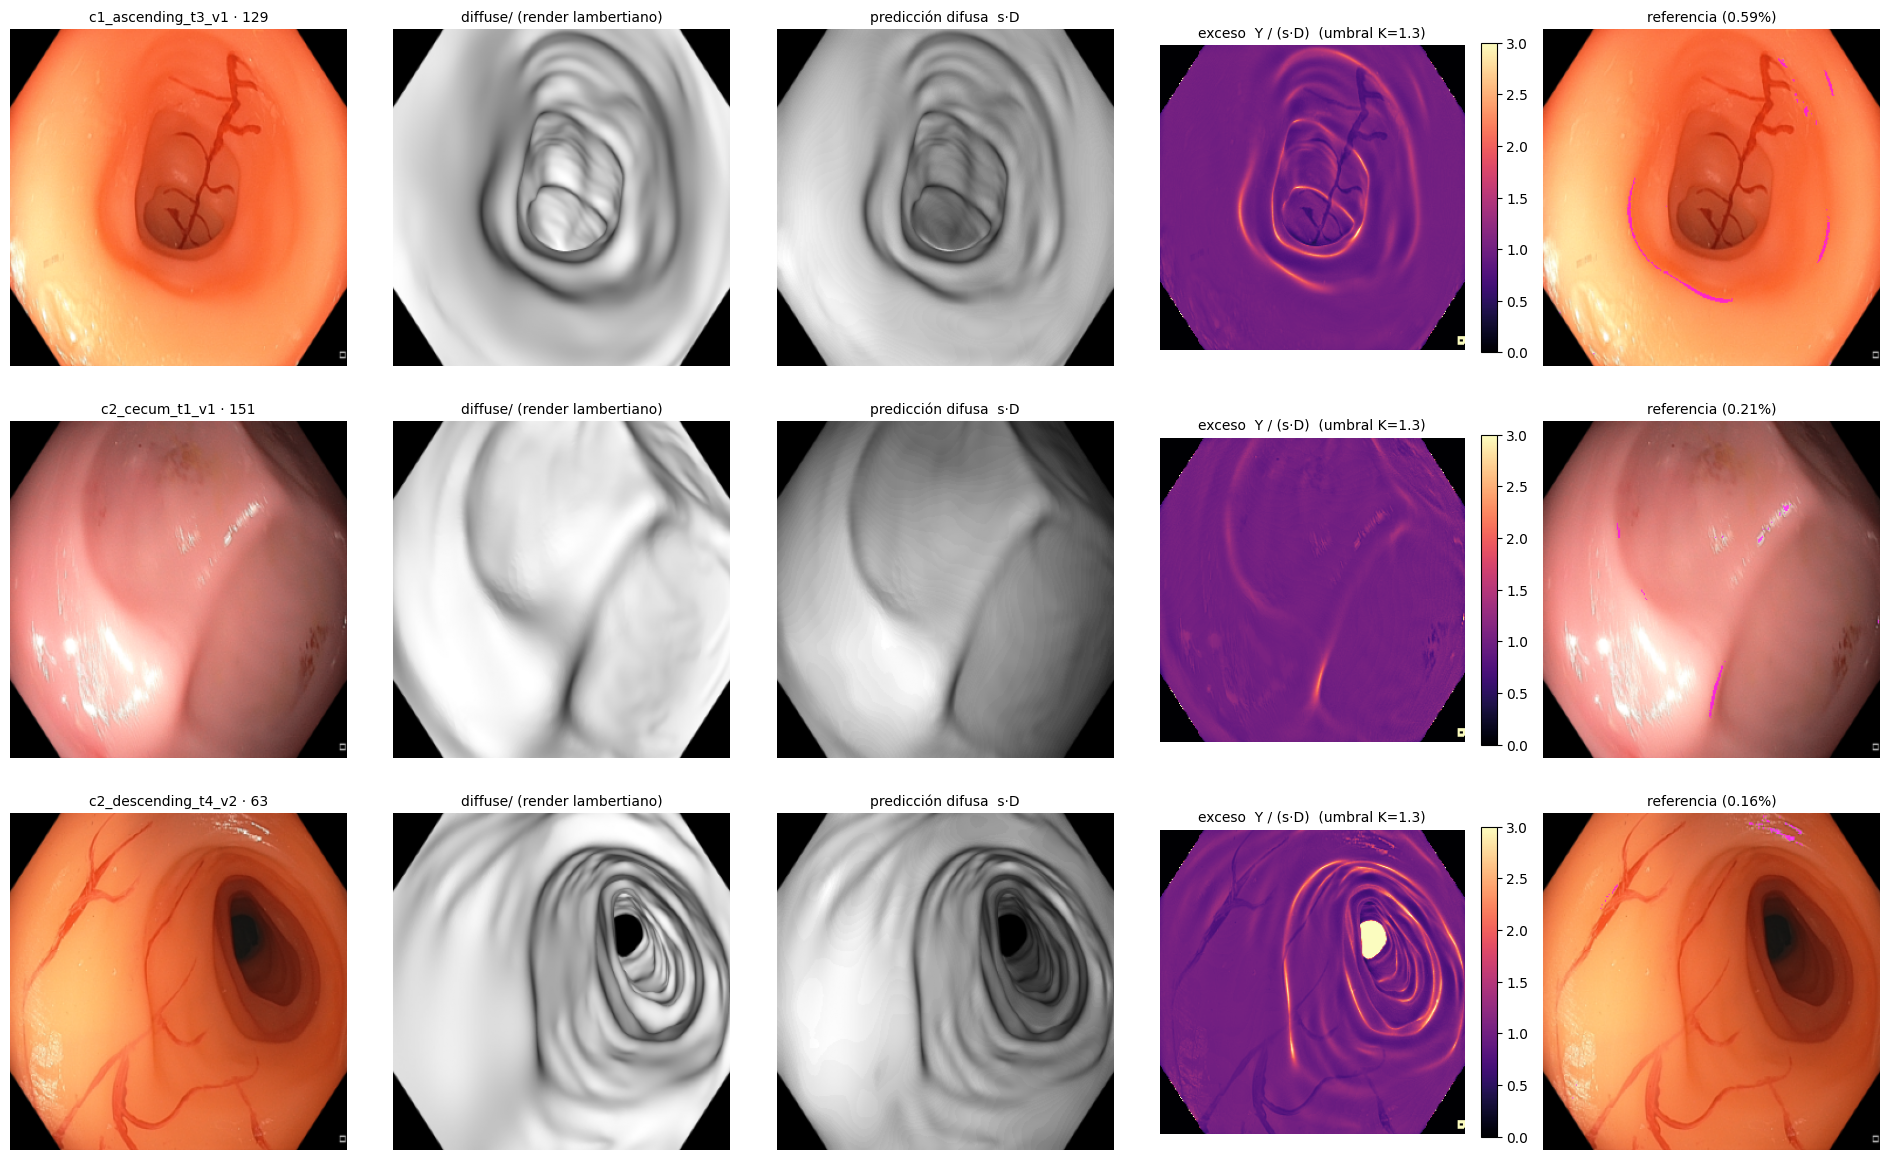

In [3]:
ejemplos = []
for v in list(videos)[:3]:
    i, rgb, dif = cm.muestra(videos[v], 3)[1]
    ejemplos.append((v, i, rgb, dif))

fig, ax = plt.subplots(len(ejemplos), 5, figsize=(19, 4 * len(ejemplos)), squeeze=False)
for fila, (v, i, rgb, dif) in zip(ax, ejemplos):
    ref, mapas = cm.referencia(rgb, dif, K, Y_MIN)
    sobre = rgb.copy(); sobre[ref] = (0.3 * sobre[ref] + 0.7 * np.array([255, 0, 255])).astype(np.uint8)
    paneles = [(rgb, f"{v} · {i}", None), (dif, "diffuse/ (render lambertiano)", "gray"),
               (mapas["prediccion"], "predicción difusa  s·D", "gray"),
               (np.clip(mapas["exceso"], 0, 3), f"exceso  Y / (s·D)  (umbral K={K})", "magma"),
               (sobre, f"referencia ({100 * ref.mean():.2f}%)", None)]
    for a, (img, t, cmap) in zip(fila, paneles):
        im = a.imshow(img, cmap=cmap); a.set_title(t, fontsize=10); a.axis("off")
        if cmap == "magma": plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

## 4. Medir los cuatro métodos

Se toman `FRAMES_POR_VIDEO` frames equiespaciados de cada video registrado y se compara cada método contra la
referencia (sección 1.7). La tabla principal es la de **videos limpios (v1, v2)**.

**Cuidado con v3:** el render difuso no tiene residuos, así que en v3 la referencia también marca los residuos claros.
Un método que "gana" en v3 puede estar marcando residuos, que es justo lo que no se quiere. En v3, un método con
buena precisión y baja sensibilidad suele ser el que **ignora** los residuos (confírmalo en la sección 5).

In [4]:
df = cm.evaluar(FRAMES_POR_VIDEO, K, Y_MIN)
res = cm.tabla_resumen(df)
cm.DIR_SALIDA.mkdir(parents=True, exist_ok=True)
df.to_csv(cm.DIR_SALIDA / "comparacion_por_frame.csv", index=False)
res.to_csv(cm.DIR_SALIDA / "comparacion_resumen.csv", index=False)
cols = ["metodo", "precision", "sensibilidad", "f1", "f1_tol", "iou", "marcado_pct", "referencia_pct", "frames"]
for grupo in res.videos.unique():
    display(Markdown(f"**{grupo}**"))
    display(res[res.videos == grupo][cols].set_index("metodo").loc[[m for m in METODOS if m in set(res.metodo)]].round(3))

c1_ascending_t3_v1: 30 frames
c2_cecum_t1_v1: 30 frames
c2_descending_t4_v2: 30 frames
c2_rectum_t1_v1: 30 frames
c2_sigmoid_t3_v2: 30 frames
c2_transverse1_t1_v1: 30 frames


**todos**

,precision,sensibilidad,f1,f1_tol,iou,marcado_pct,referencia_pct,frames
metodo,,,,,,,,
meslouhi,0.045,0.298,0.078,0.167,0.041,3.943,0.596,180.0
hsv,0.052,0.183,0.081,0.147,0.042,2.117,0.596,180.0
arnold,0.039,0.496,0.072,0.198,0.037,7.649,0.596,180.0
umbral,0.033,0.229,0.058,0.149,0.030,4.114,0.596,180.0


**limpios (v1, v2)**

,precision,sensibilidad,f1,f1_tol,iou,marcado_pct,referencia_pct,frames
metodo,,,,,,,,
meslouhi,0.045,0.298,0.078,0.167,0.041,3.943,0.596,180.0
hsv,0.052,0.183,0.081,0.147,0.042,2.117,0.596,180.0
arnold,0.039,0.496,0.072,0.198,0.037,7.649,0.596,180.0
umbral,0.033,0.229,0.058,0.149,0.030,4.114,0.596,180.0


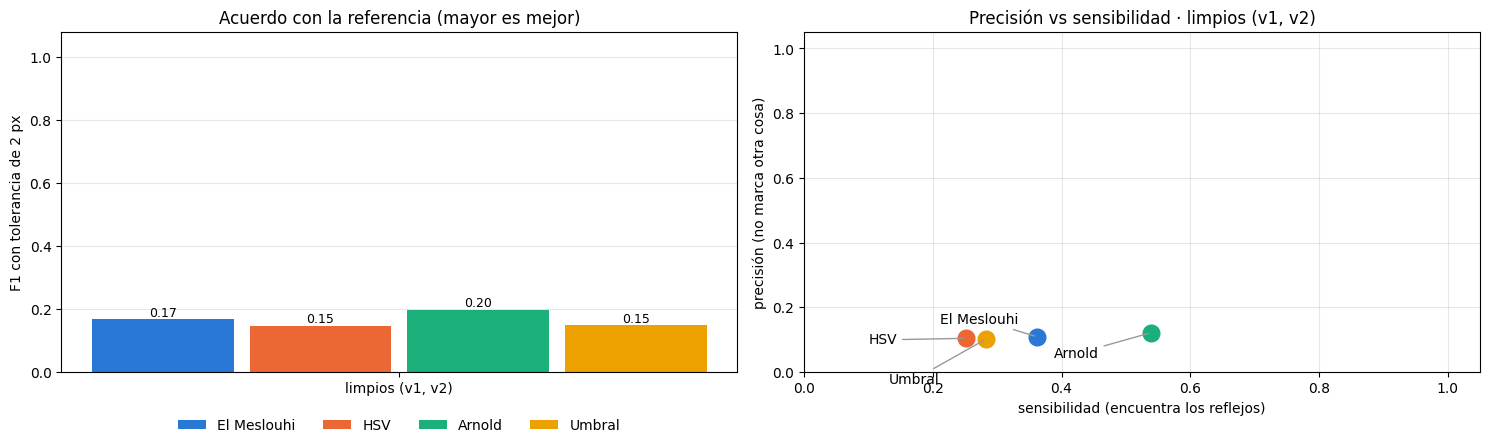

In [5]:
grupos = [g for g in ["limpios (v1, v2)", "con residuos (v3)"] if g in set(res.videos) and res[res.videos == g].frames.sum() > 0]
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
ancho = 0.8 / len(METODOS)
for j, m in enumerate(METODOS):
    vals = [res[(res.videos == g) & (res.metodo == m)].f1_tol.iloc[0] for g in grupos]
    xs = np.arange(len(grupos)) + (j - (len(METODOS) - 1) / 2) * ancho
    ax[0].bar(xs, vals, ancho * 0.9, color=COLOR[m], label=NOMBRE[m])
    for x, val in zip(xs, vals):
        ax[0].text(x, val + 0.01, f"{val:.2f}", ha="center", fontsize=9)
ax[0].set_xticks(range(len(grupos))); ax[0].set_xticklabels(grupos); ax[0].set_ylim(0, 1.08)
ax[0].set_ylabel("F1 con tolerancia de 2 px"); ax[0].set_title("Acuerdo con la referencia (mayor es mejor)")
ax[0].legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False); ax[0].grid(axis="y", alpha=0.3)

limpios = res[res.videos == (grupos[0] if grupos else "todos")]
for j, m in enumerate(METODOS):
    f = limpios[limpios.metodo == m].iloc[0]
    ax[1].plot(f.sensibilidad_tol, f.precision_tol, "o", ms=12, color=COLOR[m], label=NOMBRE[m])
    ax[1].annotate(NOMBRE[m], (f.sensibilidad_tol, f.precision_tol), xytext=(-70, 10 - 14 * j),
                   textcoords="offset points", fontsize=10, arrowprops={"arrowstyle": "-", "color": "#999999"})
ax[1].set_xlim(0, 1.05); ax[1].set_ylim(0, 1.05)
ax[1].set_xlabel("sensibilidad (encuentra los reflejos)"); ax[1].set_ylabel("precisión (no marca otra cosa)")
ax[1].set_title(f"Precisión vs sensibilidad · {grupos[0] if grupos else 'todos'}"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(cm.DIR_SALIDA / "comparacion_metricas.png", dpi=110, bbox_inches="tight"); plt.show()

## 5. Comparación visual

Para cuatro frames (incluido uno con residuos si hay videos v3), cada método contra la referencia:
**verde** = acierto, **naranja** = marcado de más (falso positivo), **azul** = reflejo no marcado (falso negativo).

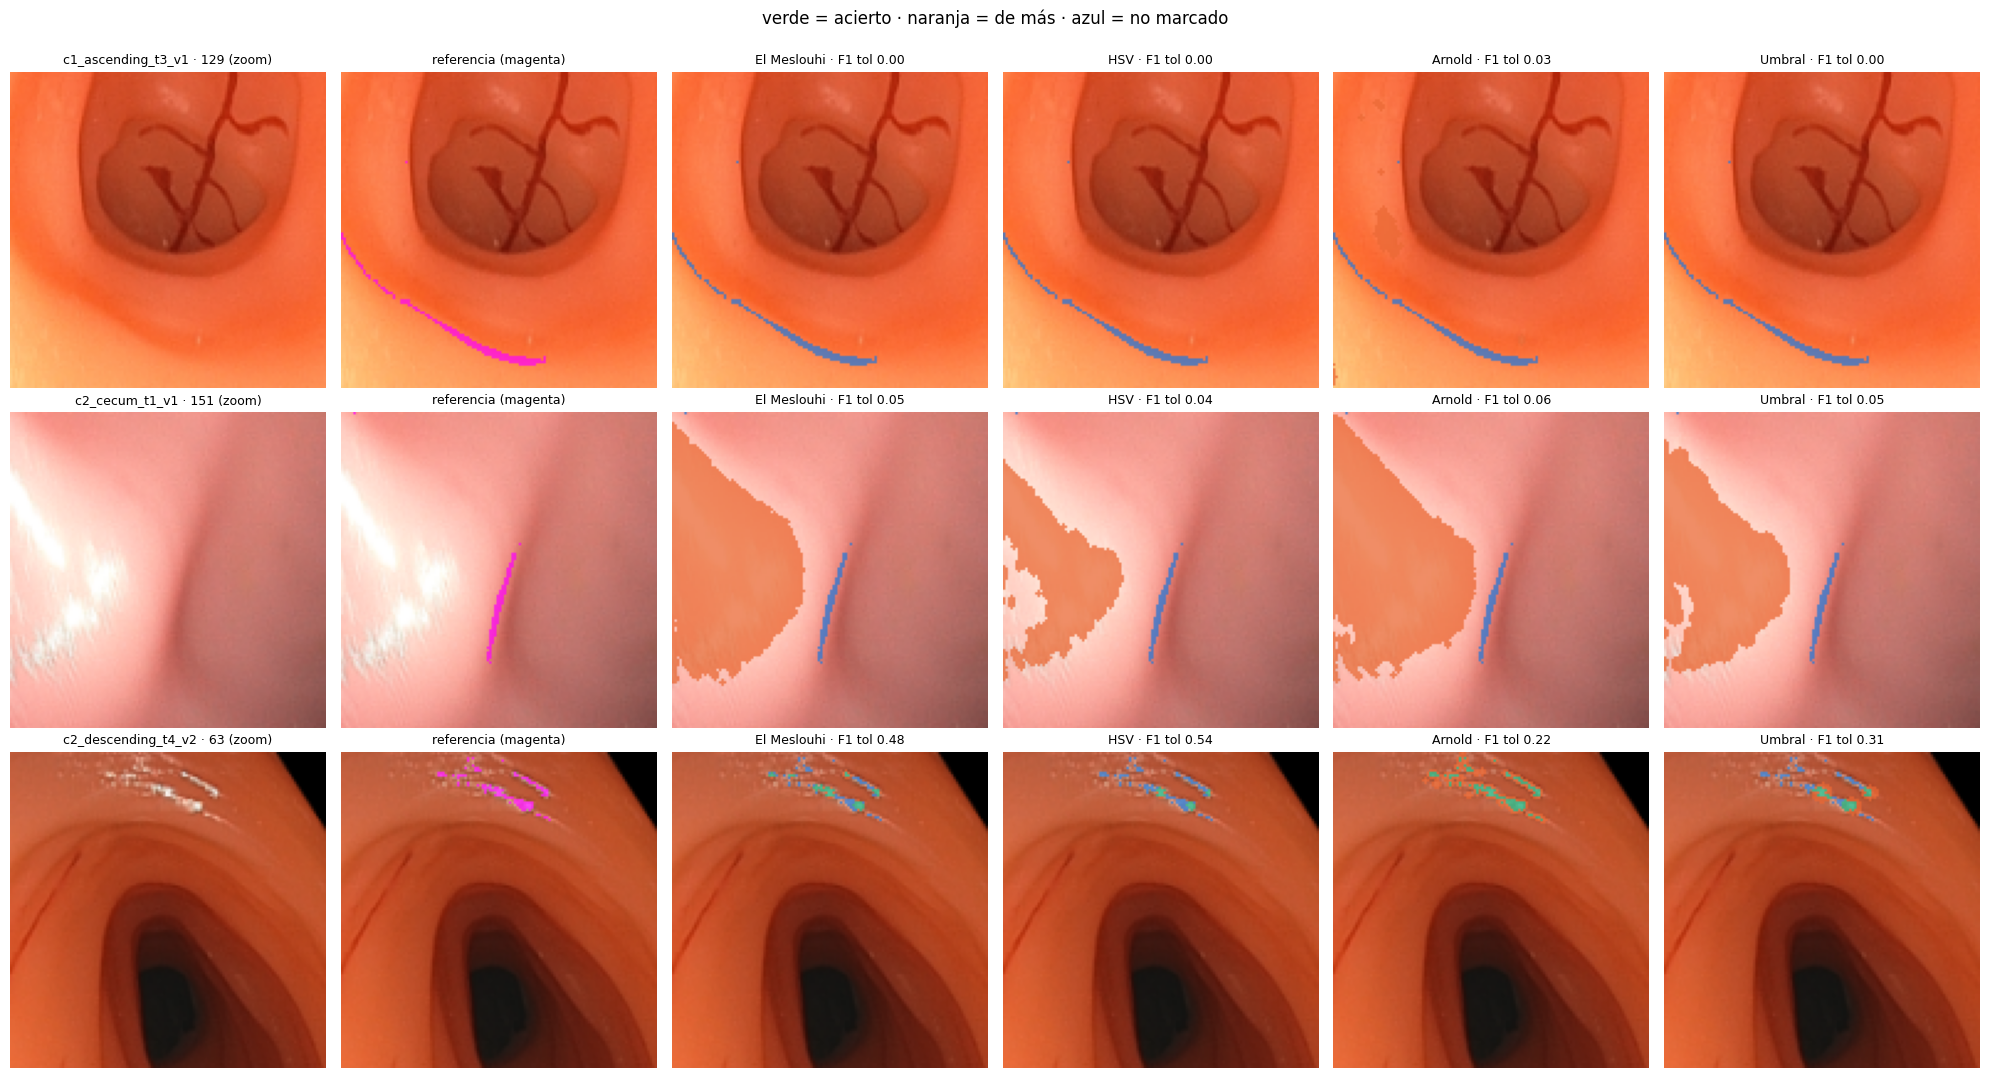

In [6]:
TP, FP, FN = np.array([27, 175, 122]), np.array([235, 104, 52]), np.array([42, 120, 214])
elegir = [v for v in videos if not v.endswith("_v3")][:3] + [v for v in videos if v.endswith("_v3")][:1]
casos = [(v, *cm.muestra(videos[v], 3)[1]) for v in elegir]

def zoom_en(m, lado=128):
    ys, xs = np.nonzero(m) if m.any() else (np.array([144]), np.array([144]))
    cy, cx = int(np.median(ys)), int(np.median(xs))
    y0, x0 = np.clip(cy - lado // 2, 0, 288 - lado), np.clip(cx - lado // 2, 0, 288 - lado)
    return lambda a: a[y0:y0 + lado, x0:x0 + lado]

fig, ax = plt.subplots(len(casos), 6, figsize=(20, 3.6 * len(casos)), squeeze=False)
for fila, (v, i, rgb, dif) in zip(ax, casos):
    ref, _ = cm.referencia(rgb, dif, K, Y_MIN)
    z = zoom_en(ref)
    fila[0].imshow(z(rgb)); fila[0].set_title(f"{v} · {i} (zoom)", fontsize=9)
    r = z(rgb).copy(); r[z(ref)] = (0.3 * r[z(ref)] + 0.7 * np.array([255, 0, 255])).astype(np.uint8)
    fila[1].imshow(r); fila[1].set_title("referencia (magenta)", fontsize=9)
    for a, (m, pred) in zip(fila[2:], cm.mascaras(rgb).items()):
        p, rr = z(pred), z(ref)
        img = z(rgb).copy().astype(float)
        for sel, c in [(p & rr, TP), (p & ~rr, FP), (~p & rr, FN)]:
            img[sel] = 0.25 * img[sel] + 0.75 * c
        f1 = cm.resumir(pd.DataFrame([{"metodo": m, **cm.comparar(pred, ref)}])).f1_tol
        a.imshow(img.astype(np.uint8)); a.set_title(f"{NOMBRE[m]} · F1 tol {f1:.2f}", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.suptitle("verde = acierto · naranja = de más · azul = no marcado", y=1.0)
plt.tight_layout(); plt.savefig(cm.DIR_SALIDA / "comparacion_visual.png", dpi=90, bbox_inches="tight"); plt.show()

## 6. Recomendación

Se elige el método con mayor F1 con tolerancia en los videos **limpios**. Es una sugerencia para discutir junto con las figuras de las secciones 3 a 5, no una decisión automática: si dos métodos quedan
cerca, conviene preferir El Meslouhi por ser el de los autores de Endo-STTN.

In [8]:
base = res[res.videos == (grupos[0] if grupos else "todos")].set_index("metodo")
mejor = base.f1_tol.idxmax()
if "meslouhi" in base.index and base.f1_tol.max() - base.f1_tol["meslouhi"] <= 0.02:
    mejor = "meslouhi"   # empate práctico (≤ 0.02): se prefiere el método de los autores de Endo-STTN
print(base[["precision_tol", "sensibilidad_tol", "f1_tol"]].round(3).sort_values("f1_tol", ascending=False).to_string())
print(f"\nSugerencia ({grupos[0] if grupos else 'todos'}): {NOMBRE[mejor]}  ->  MASCARA = \"{mejor}\"")
with open(cm.DIR_SALIDA / "comparacion_resumen.md", "w") as f:
    f.write("# Comparación de máscaras de reflejos contra la referencia de diffuse/\n\n")
    f.write(f"Referencia: Y >= {Y_MIN} y Y > {K} x predicción difusa. {FRAMES_POR_VIDEO} frames por video, "
            f"{len(videos)} videos registrados. Tolerancia en bordes: {cm.TOLERANCIA} px.\n\n")
    f.write(res.round(3).to_markdown(index=False) + f"\n\nSugerencia ({grupos[0] if grupos else 'todos'}): **{mejor}**\n")
print("Resultados ->", cm.DIR_SALIDA, sorted(p.name for p in cm.DIR_SALIDA.iterdir()))

          precision_tol  sensibilidad_tol  f1_tol
metodo                                           
arnold            0.121             0.539   0.198
meslouhi          0.109             0.362   0.167
umbral            0.101             0.282   0.149
hsv               0.104             0.251   0.147

Sugerencia (limpios (v1, v2)): Arnold  ->  MASCARA = "arnold"
Resultados -> /content/drive/MyDrive/Equipo19/re_entrenar_endo/resultados/mascaras ['comparacion_metricas.png', 'comparacion_por_frame.csv', 'comparacion_resumen.csv', 'comparacion_resumen.md', 'comparacion_visual.png']
